In [187]:
#Importing the required libraries
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.stats import norm
from scipy.stats import t
from scipy.stats import binom


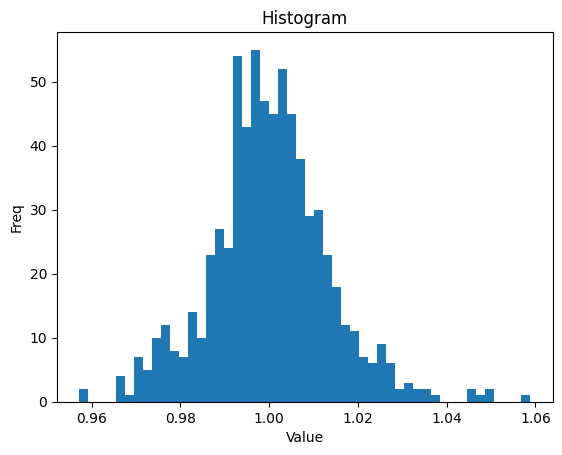

1.027707525765097
95% CI: 1.02473051640241 1.0333053075029583


In [188]:
# Problem A1
# a)

#seed 37
#Parameters
nu = 5
mu = 1
sigma = 0.01
n = 700 #Amount of samples
p = 0.975
alpha = 0.05

np.random.seed(37)
sample = mu+ sigma* np.random.standard_t(nu,n)

plt.hist(sample, bins=50)

plt.xlabel("Value")
plt.ylabel("Freq")
plt.title("Histogram")

plt.show()

sample_sorted = np.sort(sample)
F_inv = np.quantile(sample, p)


print(F_inv)
k = int(binom.ppf(alpha/2, n, p))
l = int(binom.ppf(1-alpha/2, n, p)) + 1

CI_lower = sample_sorted[k-1]
CI_upper = sample_sorted[l-1]

print("95% CI:", CI_lower, CI_upper)

val:  0.97


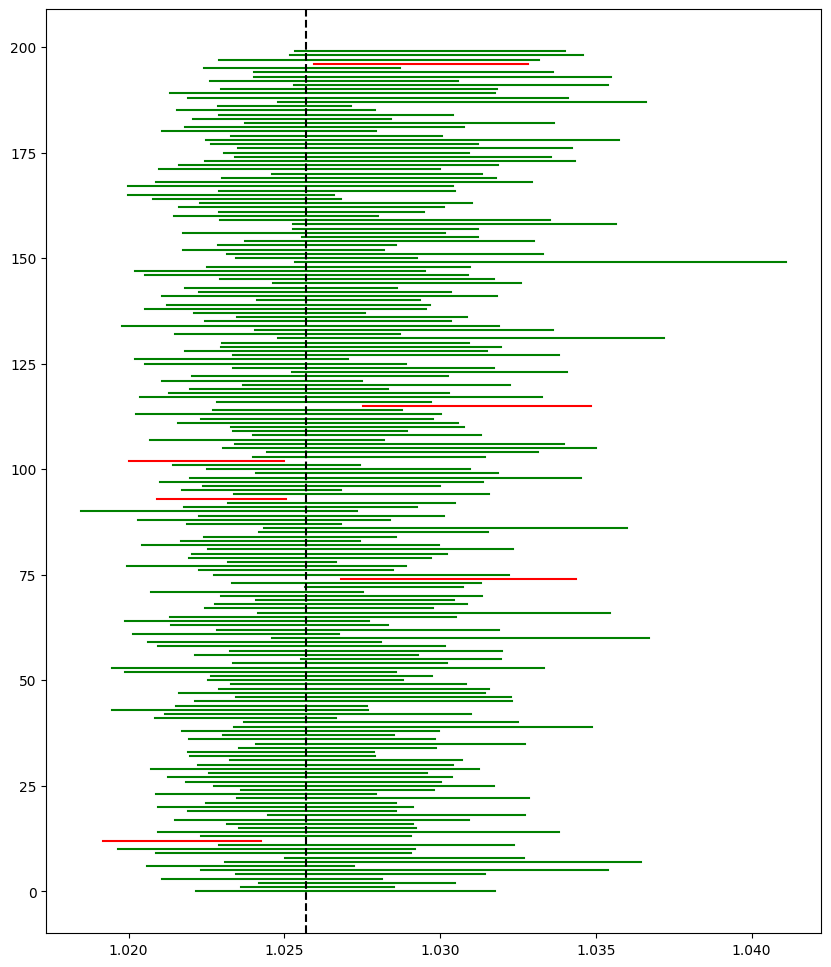

In [189]:
# Problem A1
# b)
N=200
val =0
CI_lower =np.zeros(N)
CI_upper =np.zeros(N)
y = np.arange(N)
fig, ax = plt.subplots(figsize=(10, 12))
F_inv = mu + sigma * t.ppf(p, df=nu) # Nu har jag förhopnningsvis tagit fram den teoretiska och använder sedan den

for g in range(N):
    samp = mu+ sigma* np.random.standard_t(nu,n)
    samp_sorted = np.sort(samp)

    CI_lower[g] = samp_sorted[k-1]
    CI_upper[g] = samp_sorted[l-1]   

    if CI_lower[g] <= F_inv <= CI_upper[g]:
        color = 'green'
        val= val + 1
    else:
        color = 'red'

    ax.plot(
        [CI_lower[g], CI_upper[g]],
        [y[g], y[g]],
        color=color,
        linewidth=1.5
    )

per = val/N
ax.axvline(F_inv, color='black', linestyle='--') 
print('val: ', per)

0.2570581835636321


Text(0, 0.5, 'Frequency')

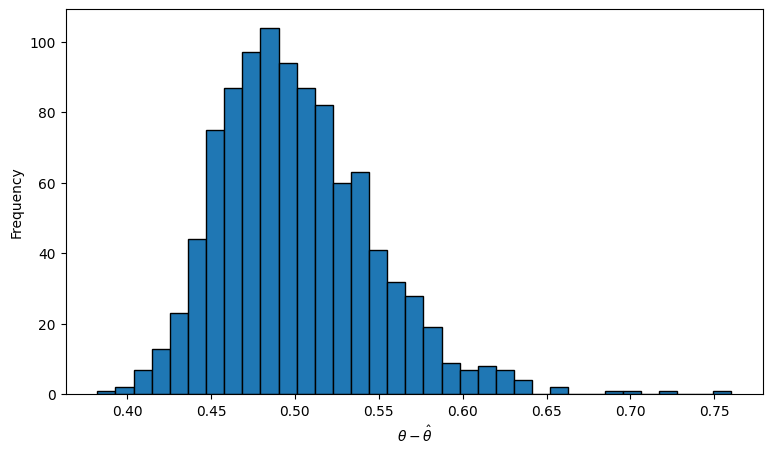

In [190]:
# A.2
# a)
#Parameters

V_0 =10
n=100
nu = 5
mu = 1
sigma= 0.01
N=1000
alpha = 0.025

R_q = t.ppf(alpha, df=nu, loc=mu, scale=sigma) 

theta = V_0*(1-R_q)

print(theta)

np.random.seed(37)

diff =[]


for h in range(N):
    R = mu+ sigma* np.random.standard_t(nu,n)
    X = V_0*(1-R)
    theta_hat =np.quantile(X,alpha)
    diff.append(theta - theta_hat)

plt.figure(figsize=(9, 5))
plt.hist(diff, bins=35, edgecolor="black")
plt.xlabel(r"$\theta-\hat{\theta}$")
plt.ylabel("Frequency")

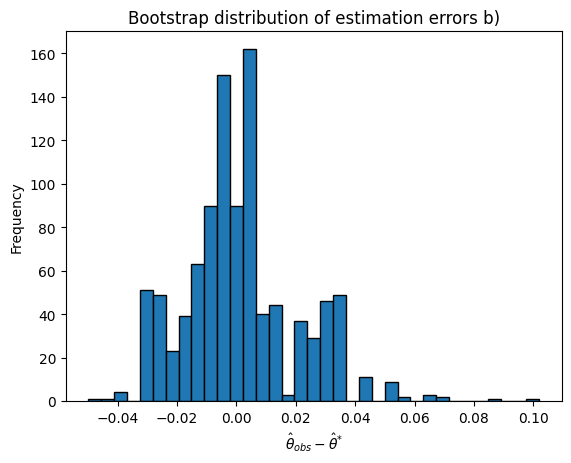

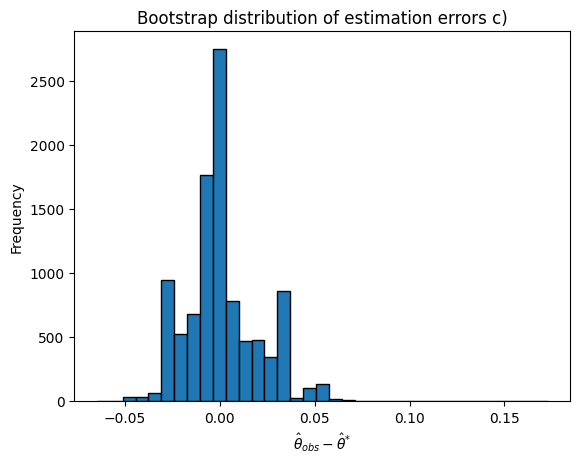

In [191]:
#b and c

np.random.seed(37)
n=700
R_obs = mu+ sigma* np.random.standard_t(nu,700) #700 different Rs
X_obs = V_0*(R_obs -1)
theta_obs =np.quantile(-X_obs,alpha)


bootstrap_samples = np.random.choice(R_obs, size=(N, n), replace=True)
X_boot = V_0 * (bootstrap_samples - 1)
theta_star_b = np.quantile(-X_boot, alpha, axis=1)
bootstrap_errors_b = theta_obs - theta_star_b
plt.hist(bootstrap_errors_b, bins=35, edgecolor='black')
plt.xlabel(r'$\hat{\theta}_{obs} - \hat{\theta}^{*}$')
plt.ylabel('Frequency')
plt.title('Bootstrap distribution of estimation errors b)')
plt.show()

N=10000
bootstrap_samples = np.random.choice(R_obs, size=(N, n), replace=True)
X_boot = V_0 * (bootstrap_samples - 1)
theta_star_c = np.quantile(-X_boot, alpha, axis=1)
bootstrap_errors_c = theta_obs - theta_star_c
plt.hist(bootstrap_errors_c, bins=35, edgecolor='black')
plt.xlabel(r'$\hat{\theta}_{obs} - \hat{\theta}^{*}$')
plt.ylabel('Frequency')
plt.title('Bootstrap distribution of estimation errors c)')
plt.show()

val:  0.095


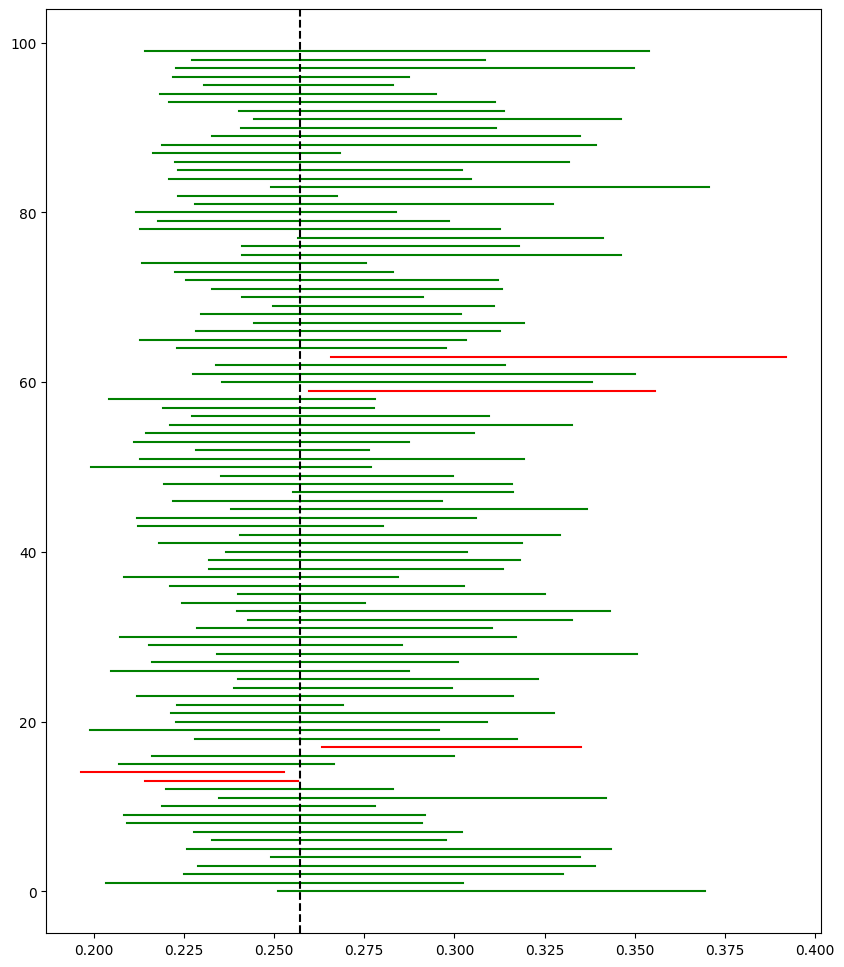

In [192]:
#d)
N=1000
n=700
alpha=0.05
val =0
CI_lower =np.zeros(n)
CI_upper =np.zeros(n)
y = np.arange(n)
fig, ax = plt.subplots(figsize=(10, 12))
F_inv=-V_0 * (t.ppf(1-p, df=nu, loc=mu, scale=sigma) - 1)
k = int(binom.ppf(alpha/2, n, p))
l = int(binom.ppf(1-alpha/2, n, p)) + 1

for g in range(100):
    samp = mu+ sigma* np.random.standard_t(nu,n)
    X = V_0 * (1 -samp)
    samp_sorted = np.sort(X)

    CI_lower[g] = samp_sorted[k-1]
    CI_upper[g] = samp_sorted[l-1]   

    if CI_lower[g] <= F_inv <= CI_upper[g]:
        color = 'green'
        val= val + 1
    else:
        color = 'red'

    ax.plot(
        [CI_lower[g], CI_upper[g]],
        [y[g], y[g]],
        color=color,
        linewidth=1.5
    )

per = val/N
ax.axvline(F_inv, color='black', linestyle='--') 
print('val: ', per)